# Source-citation integrity and validation diagnostics

This notebook checks real saved answer/source artifacts and the complete
training/validation corpus. It opens no test labels. Exact source positions and
gold-string scores are distinct from semantic support or correctness.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from types import SimpleNamespace
from collections import Counter
from dataclasses import dataclass, asdict
from functools import lru_cache
import collections, csv, hashlib, html, io, json, math, random, re, statistics, string, subprocess, sys, time, zipfile
import numpy as np
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, HTML, SVG

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir(), "Run in this repository"
FIGURES = ROOT / "assets/plots"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "svg.fonttype": "none",
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)


def sha(raw):
    return hashlib.sha256(raw).hexdigest()


def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))


def table(rows, columns, caption):
    header = "".join("<th>" + html.escape(str(c)) + "</th>" for c in columns)
    body = "".join(
        "<tr>"
        + "".join("<td>" + html.escape(str(r.get(c, ""))) + "</td>" for c in columns)
        + "</tr>"
        for r in rows
    )
    display(
        HTML(
            "<table><caption>"
            + html.escape(caption)
            + "</caption><thead><tr>"
            + header
            + "</tr></thead><tbody>"
            + body
            + "</tbody></table>"
        )
    )


def show_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / (name + ".png"), dpi=160)
    fig.savefig(FIGURES / (name + ".svg"))
    svg_path = FIGURES / (name + ".svg")
    svg_path.write_text(
        "\n".join(
            line.rstrip() for line in svg_path.read_text(encoding="utf-8").splitlines()
        )
        + "\n",
        encoding="utf-8",
        newline="\n",
    )
    display(SVG(svg_path.read_text(encoding="utf-8")))
    plt.close(fig)


print("Analysis kernel ready. No model weights loaded.")


Analysis kernel ready. No model weights loaded.


In [2]:
@dataclass
class Passage:
    id: str
    book: str
    start: int
    end: int
    text: str
    progress: float


def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())


def chunk_book(book, text, words=180, overlap=40):
    if words < 2 or not 0 <= overlap < words:
        raise ValueError("Require words >= 2 and 0 <= overlap < words")
    spans = list(re.finditer(r"\S+", text))
    result = []
    for i in range(0, len(spans), words - overlap):
        j = min(i + words, len(spans))
        start, end = spans[i].start(), spans[j - 1].end()
        result.append(
            Passage(
                f"{book}:{start}-{end}",
                book,
                start,
                end,
                text[start:end],
                i / max(1, len(spans)),
            )
        )
        if j == len(spans):
            break
    return result


In [3]:
def expand_passage(passage, text, characters=700):
    if not isinstance(characters, int) or characters < 0:
        raise ValueError("Expansion must be a nonnegative integer")
    if text[passage.start : passage.end] != passage.text:
        raise ValueError("Cannot expand a passage that mismatches its source")
    start = max(0, passage.start - characters)
    end = min(len(text), passage.end + characters)
    # Avoid cutting words while retaining exact source coordinates.
    while start > 0 and not text[start - 1].isspace():
        start -= 1
    while end < len(text) and not text[end].isspace():
        end += 1
    return Passage(
        f"{passage.book}:{start}-{end}",
        passage.book,
        start,
        end,
        text[start:end],
        passage.progress,
    )


In [4]:
def finite_number(value):
    if type(value) not in (int, float):
        return False
    try:
        return math.isfinite(value)
    except OverflowError:
        return False


def digest_policy(policy):
    raw = json.dumps(
        policy,
        sort_keys=True,
        separators=(",", ":"),
        ensure_ascii=False,
        allow_nan=False,
    ).encode("utf-8")
    return hashlib.sha256(raw).hexdigest()


def policy_from_selection(selection):
    if (
        not isinstance(selection, dict)
        or not isinstance(selection.get("selected"), dict)
        or not isinstance(selection.get("models"), dict)
    ):
        raise ValueError(
            "Frozen selection must contain models and selected policy objects"
        )
    selected = selection["selected"]
    if not {"config", "threshold", "rank_penalty"} <= set(selected):
        raise ValueError("Frozen selection is missing required policy fields")
    policy = {
        "models": selection["models"],
        "config": selected["config"],
        "threshold": selected["threshold"],
        "rank_penalty": selected["rank_penalty"],
    }
    validate_policy(policy)
    return policy


def validate_policy(policy):
    if not isinstance(policy, dict) or not {
        "models",
        "config",
        "threshold",
        "rank_penalty",
    } <= set(policy):
        raise ValueError("Answer policy must contain required policy fields")
    if (
        not finite_number(policy["threshold"])
        or not finite_number(policy["rank_penalty"])
        or policy["rank_penalty"] < 0
    ):
        raise ValueError("Invalid finite selection parameters")
    config = policy["config"]
    if not isinstance(config, dict) or not {
        "words",
        "overlap",
        "k",
        "expand",
        "sliding",
    } <= set(config):
        raise ValueError("Answer policy has incomplete chunk configuration")
    if (
        type(config["words"]) is not int
        or type(config["overlap"]) is not int
        or not 0 <= config["overlap"] < config["words"]
        or type(config["k"]) is not int
        or config["k"] < 1
        or type(config["expand"]) is not int
        or config["expand"] < 0
        or type(config["sliding"]) is not bool
    ):
        raise ValueError("Invalid persisted chunk or reader configuration")
    models = policy["models"]
    if (
        not isinstance(models, dict)
        or not isinstance(models.get("reader"), str)
        or not models["reader"]
        or any(
            not isinstance(models.get(key), str)
            or not re.fullmatch(r"[0-9a-f]{40}", models[key])
            for key in ("embedding_revision", "reader_revision", "reranker_revision")
        )
    ):
        raise ValueError("Missing exact persisted model revisions")


def verify_artifact(artifact, text, expected_selection=None):
    if not isinstance(artifact, dict):
        raise ValueError("Answer artifact must be an object")
    if not isinstance(text, str):
        raise ValueError("Source must be Unicode text")
    if not {"policy", "policy_sha256", "source_sha256", "book", "abstained"} <= set(
        artifact
    ):
        raise ValueError("Answer artifact is missing required fields")
    if (
        type(artifact.get("artifact_schema")) is not int
        or artifact["artifact_schema"] != 1
    ):
        raise ValueError("Unsupported answer artifact schema")
    book = artifact.get("book")
    if not isinstance(book, str) or not re.fullmatch(
        r"[A-Za-z0-9][A-Za-z0-9_-]*", book
    ):
        raise ValueError("Invalid source book identifier")
    if (
        artifact.get("source_sha256")
        != hashlib.sha256(text.encode("utf-8")).hexdigest()
    ):
        raise ValueError("Answer source fingerprint changed")
    policy = artifact["policy"]
    validate_policy(policy)
    if artifact.get("policy_sha256") != digest_policy(policy):
        raise ValueError("Answer policy fingerprint changed")
    if expected_selection is not None and policy != policy_from_selection(
        expected_selection
    ):
        raise ValueError("Artifact differs from the expected frozen selection")
    config = policy["config"]
    if type(artifact.get("abstained")) is not bool:
        raise ValueError("Abstention status must be explicit")
    if artifact["abstained"]:
        if artifact.get("answer") is not None or any(
            key in artifact for key in ("citation", "answer_start", "answer_end")
        ):
            raise ValueError("Abstention cannot carry an accepted answer")
        return {
            "valid": True,
            "abstained": True,
            "source_exact": None,
            "frozen_policy_matches": expected_selection is not None,
            "semantic_correctness_verified": False,
            "authenticity_verified": False,
        }
    answer, start, end = (
        artifact.get("answer"),
        artifact.get("answer_start"),
        artifact.get("answer_end"),
    )
    citation = artifact.get("citation")
    match = (
        re.fullmatch(r"([A-Za-z0-9][A-Za-z0-9_-]*):(\d+)-(\d+)", citation)
        if isinstance(citation, str)
        else None
    )
    if (
        not match
        or match[1] != book
        or type(start) is not int
        or type(end) is not int
        or not 0 <= int(match[2]) <= start < end <= int(match[3]) <= len(text)
        or not isinstance(answer, str)
        or text[start:end] != answer
    ):
        raise ValueError("Answer does not match cited source coordinates")
    if (
        not finite_number(artifact.get("null_margin"))
        or artifact["null_margin"] <= policy["threshold"]
        or type(artifact.get("retrieval_rank")) is not int
        or not 1 <= artifact["retrieval_rank"] <= config["k"]
    ):
        raise ValueError("Answer lacks finite eligible reader provenance")
    expected_evidence = {"citation": citation, "answer_start": start, "answer_end": end}
    if artifact.get("evidence") != expected_evidence:
        raise ValueError("Evidence metadata disagrees with answer coordinates")
    passages = chunk_book(book, text, config["words"], config["overlap"])
    known = {
        expand_passage(p, text, config["expand"]).id if config["expand"] else p.id
        for p in passages
    }
    if citation not in known:
        raise ValueError("Citation does not match declared source chunk geometry")
    return {
        "valid": True,
        "abstained": False,
        "source_exact": True,
        "frozen_policy_matches": expected_selection is not None,
        "selection_decision_recomputed": False,
        "semantic_correctness_verified": False,
        "authenticity_verified": False,
    }


def make_artifact(result, text, book, selection):
    if not isinstance(result, dict):
        raise ValueError("Answer result must be an object")
    policy = policy_from_selection(selection)
    artifact = {
        **result,
        "artifact_schema": 1,
        "book": book,
        "source_sha256": hashlib.sha256(text.encode("utf-8")).hexdigest(),
        "policy": policy,
        "policy_sha256": digest_policy(policy),
    }
    verify_artifact(artifact, text, selection)
    return artifact


def audit_answer(path, source_directory, expected_selection=None):
    def unique_pairs(pairs):
        result = {}
        for key, value in pairs:
            if key in result:
                raise ValueError("Duplicate answer artifact key")
            result[key] = value
        return result

    with Path(path).open("rb") as source:
        raw = source.read(1_000_001)
    if len(raw) > 1_000_000:
        raise ValueError("Answer artifact is unexpectedly large")
    artifact = json.loads(raw.decode("utf-8"), object_pairs_hook=unique_pairs)
    if not isinstance(artifact, dict):
        raise ValueError("Answer artifact must be an object")
    book = artifact.get("book")
    if not isinstance(book, str) or not re.fullmatch(
        r"[A-Za-z0-9][A-Za-z0-9_-]*", book
    ):
        raise ValueError("Invalid source book identifier")
    text = (Path(source_directory) / f"{book}.txt").read_text(encoding="utf-8")
    return verify_artifact(artifact, text, expected_selection)


In [5]:
actual = ROOT / "data/interim/v4-answer-artifact.json"
tampered = ROOT / "data/interim/v4-answer-artifact-tampered.json"
frozen = read_json("docs/v2-validation-selection.json")
receipts = []
if actual.exists() and (ROOT / "data/processed/dorian.txt").exists():
    receipts.append(
        {
            "artifact": "actual saved validation answer",
            **audit_answer(actual, ROOT / "data/processed", frozen),
        }
    )
    if tampered.exists():
        try:
            audit_answer(tampered, ROOT / "data/processed", frozen)
            raise AssertionError("Tampered artifact unexpectedly passed")
        except ValueError as exc:
            receipts.append(
                {
                    "artifact": "previously tampered copy",
                    "valid": False,
                    "reason": str(exc),
                }
            )
    table(
        receipts,
        sorted(set().union(*(set(r) for r in receipts))),
        "Actual artifact replay audits; no model rerun",
    )
else:
    print(
        "Private artifacts absent. Recorded actual CLI receipt:",
        read_json("docs/v4-artifact-cli-smoke.json"),
    )
print("Only audit flags are displayed, never private question/answer/passage text.")


abstained,artifact,authenticity_verified,frozen_policy_matches,reason,selection_decision_recomputed,semantic_correctness_verified,source_exact,valid
False,actual saved validation answer,False,True,,False,False,True,True
,previously tampered copy,,,Answer does not match cited source coordinates,,,,False


Only audit flags are displayed, never private question/answer/passage text.


## Source and identity invariants

Actual training/validation annotation aggregates expose repeated upstream IDs;
canonical story/row IDs stay unique. No test labels are used. A real source audit
below also checks deliberate offset/text mutations rather than claiming semantic
accuracy from citation consistency.


In [6]:
summary = read_json("docs/data-summary.json")
table(
    [
        {
            "split": split,
            "QA": r["questions"],
            "duplicate upstream IDs": r["duplicate_original_ids"],
            "canonical IDs unique": r["canonical_ids_unique"],
        }
        for split, r in summary["annotations"].items()
    ],
    ["split", "QA", "duplicate upstream IDs", "canonical IDs unique"],
    "Actual all-training/validation identity audit",
)


split,QA,duplicate upstream IDs,canonical IDs unique
train,7883,5,True
validation,2372,5,True


## Source guards for generated answers

The source guard rejects empty evidence, invalid offsets and negative slices
even when Python could return matching text from a negative slice. It does not
certify the meaning of a generated answer. Full-data answer results are pending.


In [7]:
def verify_story(story):
    if not isinstance(story, dict) or not isinstance(story.get("text"), str):
        raise ValueError("Expected a story with source text")
    if sha(story["text"].encode()) != story.get("source_sha256"):
        raise ValueError("Story source hash mismatch")
    sections = story.get("sections")
    if not isinstance(sections, list) or not sections:
        raise ValueError("Story must contain source sections")
    for section in sections:
        if not isinstance(section, dict):
            raise ValueError("Expected a source section object")
        start, end = section.get("start"), section.get("end")
        if (
            type(start) is not int
            or type(end) is not int
            or not 0 <= start < end <= len(story["text"])
        ):
            raise ValueError("Invalid source section coordinates")
        if story["text"][start:end] != section.get("text"):
            raise ValueError("Story section source-offset mismatch")
        if not isinstance(section.get("id"), str) or not section["id"]:
            raise ValueError("Source section ID required")
    if len({s["id"] for s in sections}) != len(sections):
        raise ValueError("Duplicate source section IDs")


check,passed
train real source stories,200
validation real source stories,54
deliberate source mutations rejected,3


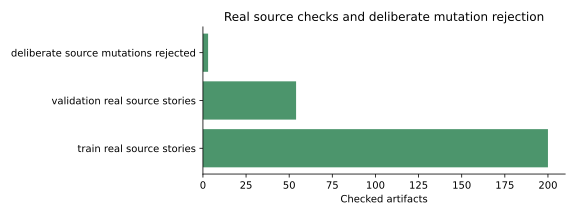

In [8]:
from src.narrative_training import load_split

staged = ROOT / "data/interim/full-fairytale-v6"
checks = []
if staged.exists():
    for split in ("train", "validation"):
        stories, _ = load_split(staged, split)
        for story in stories.values():
            verify_story(story)
        checks.append({"check": split + " real source stories", "passed": len(stories)})
    example = next(iter(stories.values()))
    mutations = [
        {**example, "text": example["text"] + "x"},
        {**example, "sections": []},
        {
            **example,
            "sections": [{**example["sections"][0], "start": -1}]
            + example["sections"][1:],
        },
    ]
    rejected = 0
    for mutation in mutations:
        try:
            verify_story(mutation)
        except ValueError:
            rejected += 1
    assert rejected == len(mutations)
    checks.append({"check": "deliberate source mutations rejected", "passed": rejected})
    table(
        checks,
        ["check", "passed"],
        "Actually executed source invariants; not QA accuracy",
    )
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.barh(
        [r["check"] for r in checks], [r["passed"] for r in checks], color="#4c956c"
    )
    ax.set(
        xlabel="Checked artifacts",
        title="Real source checks and deliberate mutation rejection",
    )
    show_figure(fig, "source-integrity-checks")
else:
    print("Private source corpus unavailable; no source checks invented.")


## Interpreting answer errors

Retrieval can miss human-linked evidence, context assembly can truncate it, and
generation can produce an unsupported answer despite valid source coordinates.
Annotation may omit alternative evidence. Complete model predictions will be
analysed on validation; test cases cannot choose policies. Four repeatedly reused
authored unknown controls are not a general abstention-calibration benchmark.
